<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%201-10/Experiment%209%3A%20Multilayer%20Perceptron%20Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


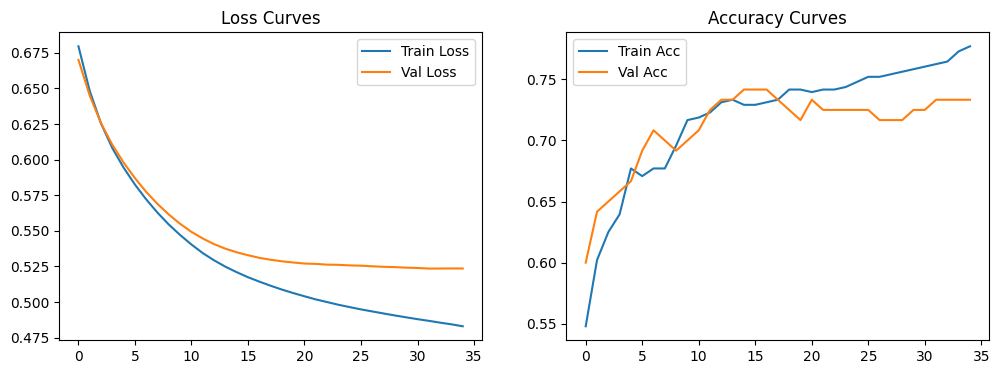

Accuracy : 0.7100
Precision: 0.7895
Recall   : 0.7258
F1-Score : 0.7563


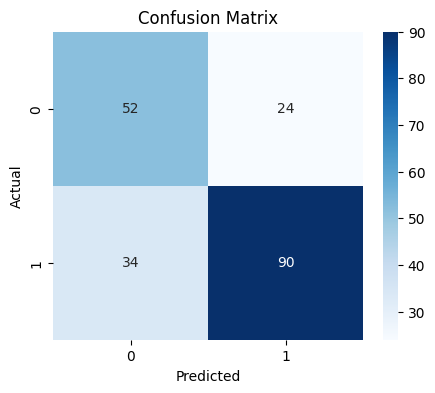


Hidden-Layer Width Comparison:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Width   8 -> Test Accuracy: 0.7100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Width  32 -> Test Accuracy: 0.6900


Width 128 -> Test Accuracy: 0.7000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

n = 800
df = pd.DataFrame({
    'tenure': np.random.randint(1, 72, n),
    'monthly_charges': np.random.uniform(20, 120, n),
    'complaints': np.random.poisson(1.2, n),
    'data_usage': np.random.uniform(1, 50, n),
    'contract': np.random.choice(['Month-to-month', 'One year', 'Two year'], n, p=[0.55, 0.25, 0.20])
})
logit = -1.5 + 0.03*df['monthly_charges'] - 0.04*df['tenure'] + 0.6*df['complaints'] + (df['contract'] == 'Month-to-month')*1.2
df['Churn'] = (np.random.rand(n) < (1 / (1 + np.exp(-logit)))).astype(int)

X = df.drop('Churn', axis=1)
y = df['Churn'].values
pre = ColumnTransformer([
    ('num', StandardScaler(), ['tenure', 'monthly_charges', 'complaints', 'data_usage']),
    ('cat', OneHotEncoder(drop='first'), ['contract'])
])
X_proc = pre.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_proc, y, test_size=0.25, random_state=42)

def build_mlp(width=32):
    model = keras.Sequential([
        keras.layers.Dense(width, activation='relu', input_shape=(X_train.shape[1],)),
        keras.layers.Dense(width // 2, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

mlp = build_mlp(32)
hist = mlp.fit(X_train, y_train, validation_split=0.2, epochs=35, batch_size=32, verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history['loss'], label='Train Loss')
axes[0].plot(hist.history['val_loss'], label='Val Loss')
axes[0].set_title("Loss Curves"); axes[0].legend()
axes[1].plot(hist.history['accuracy'], label='Train Acc')
axes[1].plot(hist.history['val_accuracy'], label='Val Acc')
axes[1].set_title("Accuracy Curves"); axes[1].legend()
plt.show()

y_pred = (mlp.predict(X_test, verbose=0) >= 0.5).astype(int).ravel()
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred):.4f}")

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

print("\nHidden-Layer Width Comparison:")
for w in [8, 32, 128]:
    m = build_mlp(w)
    m.fit(X_train, y_train, epochs=30, batch_size=32, verbose=0)
    acc = accuracy_score(y_test, (m.predict(X_test, verbose=0) >= 0.5).astype(int))
    print(f"Width {w:3d} -> Test Accuracy: {acc:.4f}")